In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.manifold import MDS
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_samples,
    silhouette_score,
)
from sklearn.metrics.pairwise import euclidean_distances

In [2]:
employeeProd = pd.read_csv("/content/Cleaned_data_IBM_HR - WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [3]:
print("Dataset shape:", employeeProd.shape)
print(employeeProd.head())
print("Missing values:", employeeProd.isnull().sum().sum())

Dataset shape: (999, 30)
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

  EducationField  EmployeeNumber  EnvironmentSatisfaction  Gender  HourlyRate  \
0  Life Sciences               1                        2  Female          94   
1  Life Sciences               2                        3    Male          61   
2          Other               4                        4    Male          92   
3  Life Sciences               5                        4  Female          56   
4        Medical               7                        1    Male          40   

   ...  PerformanceRating  RelationshipSati

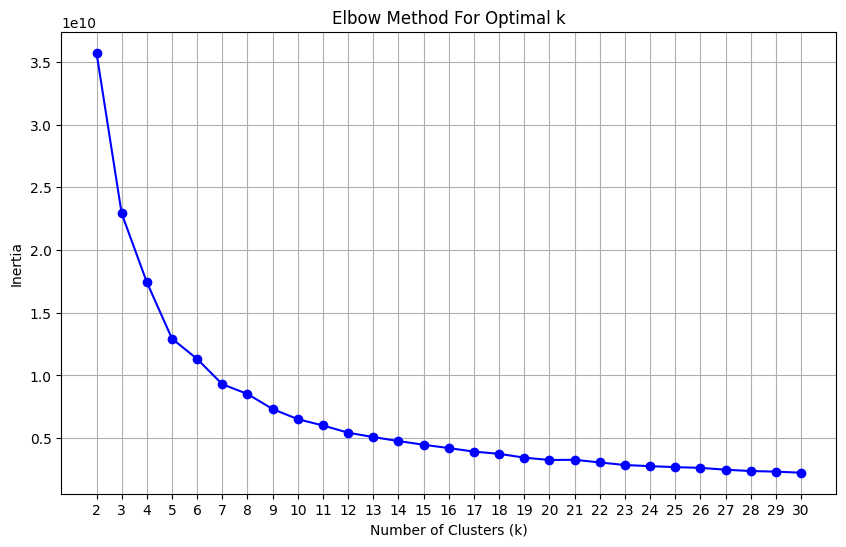

In [6]:
inertias = []

k_values = range(2, 31)

features_numeric = employeeProd.select_dtypes(include=[np.number])

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(features_numeric)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(list(k_values), inertias, marker='o', linestyle='-', color='b')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

After running the code i have determined to use 7 as our K value.

In [11]:
k_optimal = 7
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
employeeProd['cluster'] = kmeans.fit_predict(features_numeric)

for cluster, group in employeeProd.groupby("cluster"):
    print(f"Cluster {cluster} (size: {len(group)}):")
    sample_size = min(5, len(group))
    sample_employees = group.sample(sample_size, random_state=42)
    for idx, row in sample_employees.iterrows():
        print(f"	Employee Index {idx}: Age {row['Age']}, Department {row['Department']}, YearsAtCompany {row['YearsAtCompany']}")
    print()

Cluster 0 (size: 194):
	Employee Index 691: Age 40, Department Research & Development, YearsAtCompany 1
	Employee Index 107: Age 25, Department Sales, YearsAtCompany 6
	Employee Index 790: Age 33, Department Research & Development, YearsAtCompany 3
	Employee Index 501: Age 30, Department Research & Development, YearsAtCompany 1
	Employee Index 350: Age 42, Department Human Resources, YearsAtCompany 3

Cluster 1 (size: 185):
	Employee Index 87: Age 51, Department Research & Development, YearsAtCompany 4
	Employee Index 240: Age 39, Department Research & Development, YearsAtCompany 3
	Employee Index 823: Age 29, Department Research & Development, YearsAtCompany 7
	Employee Index 529: Age 38, Department Research & Development, YearsAtCompany 9
	Employee Index 777: Age 21, Department Research & Development, YearsAtCompany 1

Cluster 2 (size: 207):
	Employee Index 800: Age 28, Department Research & Development, YearsAtCompany 1
	Employee Index 61: Age 38, Department Research & Development, 